In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# 全局风格
import seaborn as sns
sns.set_theme(style="whitegrid", palette="Set2") 
plt.rcParams["figure.dpi"] = 110
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'SimSun']
plt.rcParams["axes.unicode_minus"] = False
from pandas.plotting import parallel_coordinates
from sklearn.preprocessing import RobustScaler

In [6]:
df = pd.read_csv('test.csv', encoding='utf-8-sig')
df.head()
# 查看每列缺失值数量
missing_count = df.isnull().sum()
print("每列缺失值数量统计：")
print(missing_count)

每列缺失值数量统计：
age                     0
gender                  0
academic_year           0
study_hours_per_day     0
exam_pressure           0
academic_performance    0
stress_level            0
anxiety_score           0
depression_score        0
sleep_hours             0
physical_activity       0
social_support          0
screen_time             0
internet_usage          0
financial_stress        0
family_expectation      0
burnout_score           0
mental_health_index     0
risk_level              0
dropout_risk            0
dtype: int64


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 全局风格
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.unicode_minus"] = False

df = pd.read_csv("test.csv", encoding="utf-8-sig")

# 列分类
num_cols = [
    "age", "academic_year", "study_hours_per_day", "exam_pressure",
    "academic_performance", "stress_level", "anxiety_score", "depression_score",
    "sleep_hours", "physical_activity", "social_support", "screen_time",
    "internet_usage", "financial_stress", "family_expectation",
    "burnout_score", "mental_health_index", "dropout_risk"
]
cat_cols = ["gender", "academic_year", "risk_level"]

# risk_level 设为有序类别，便于配色
order_risk = ["Low", "Medium", "High"]
df["risk_level"] = pd.Categorical(df["risk_level"], categories=order_risk, ordered=True)


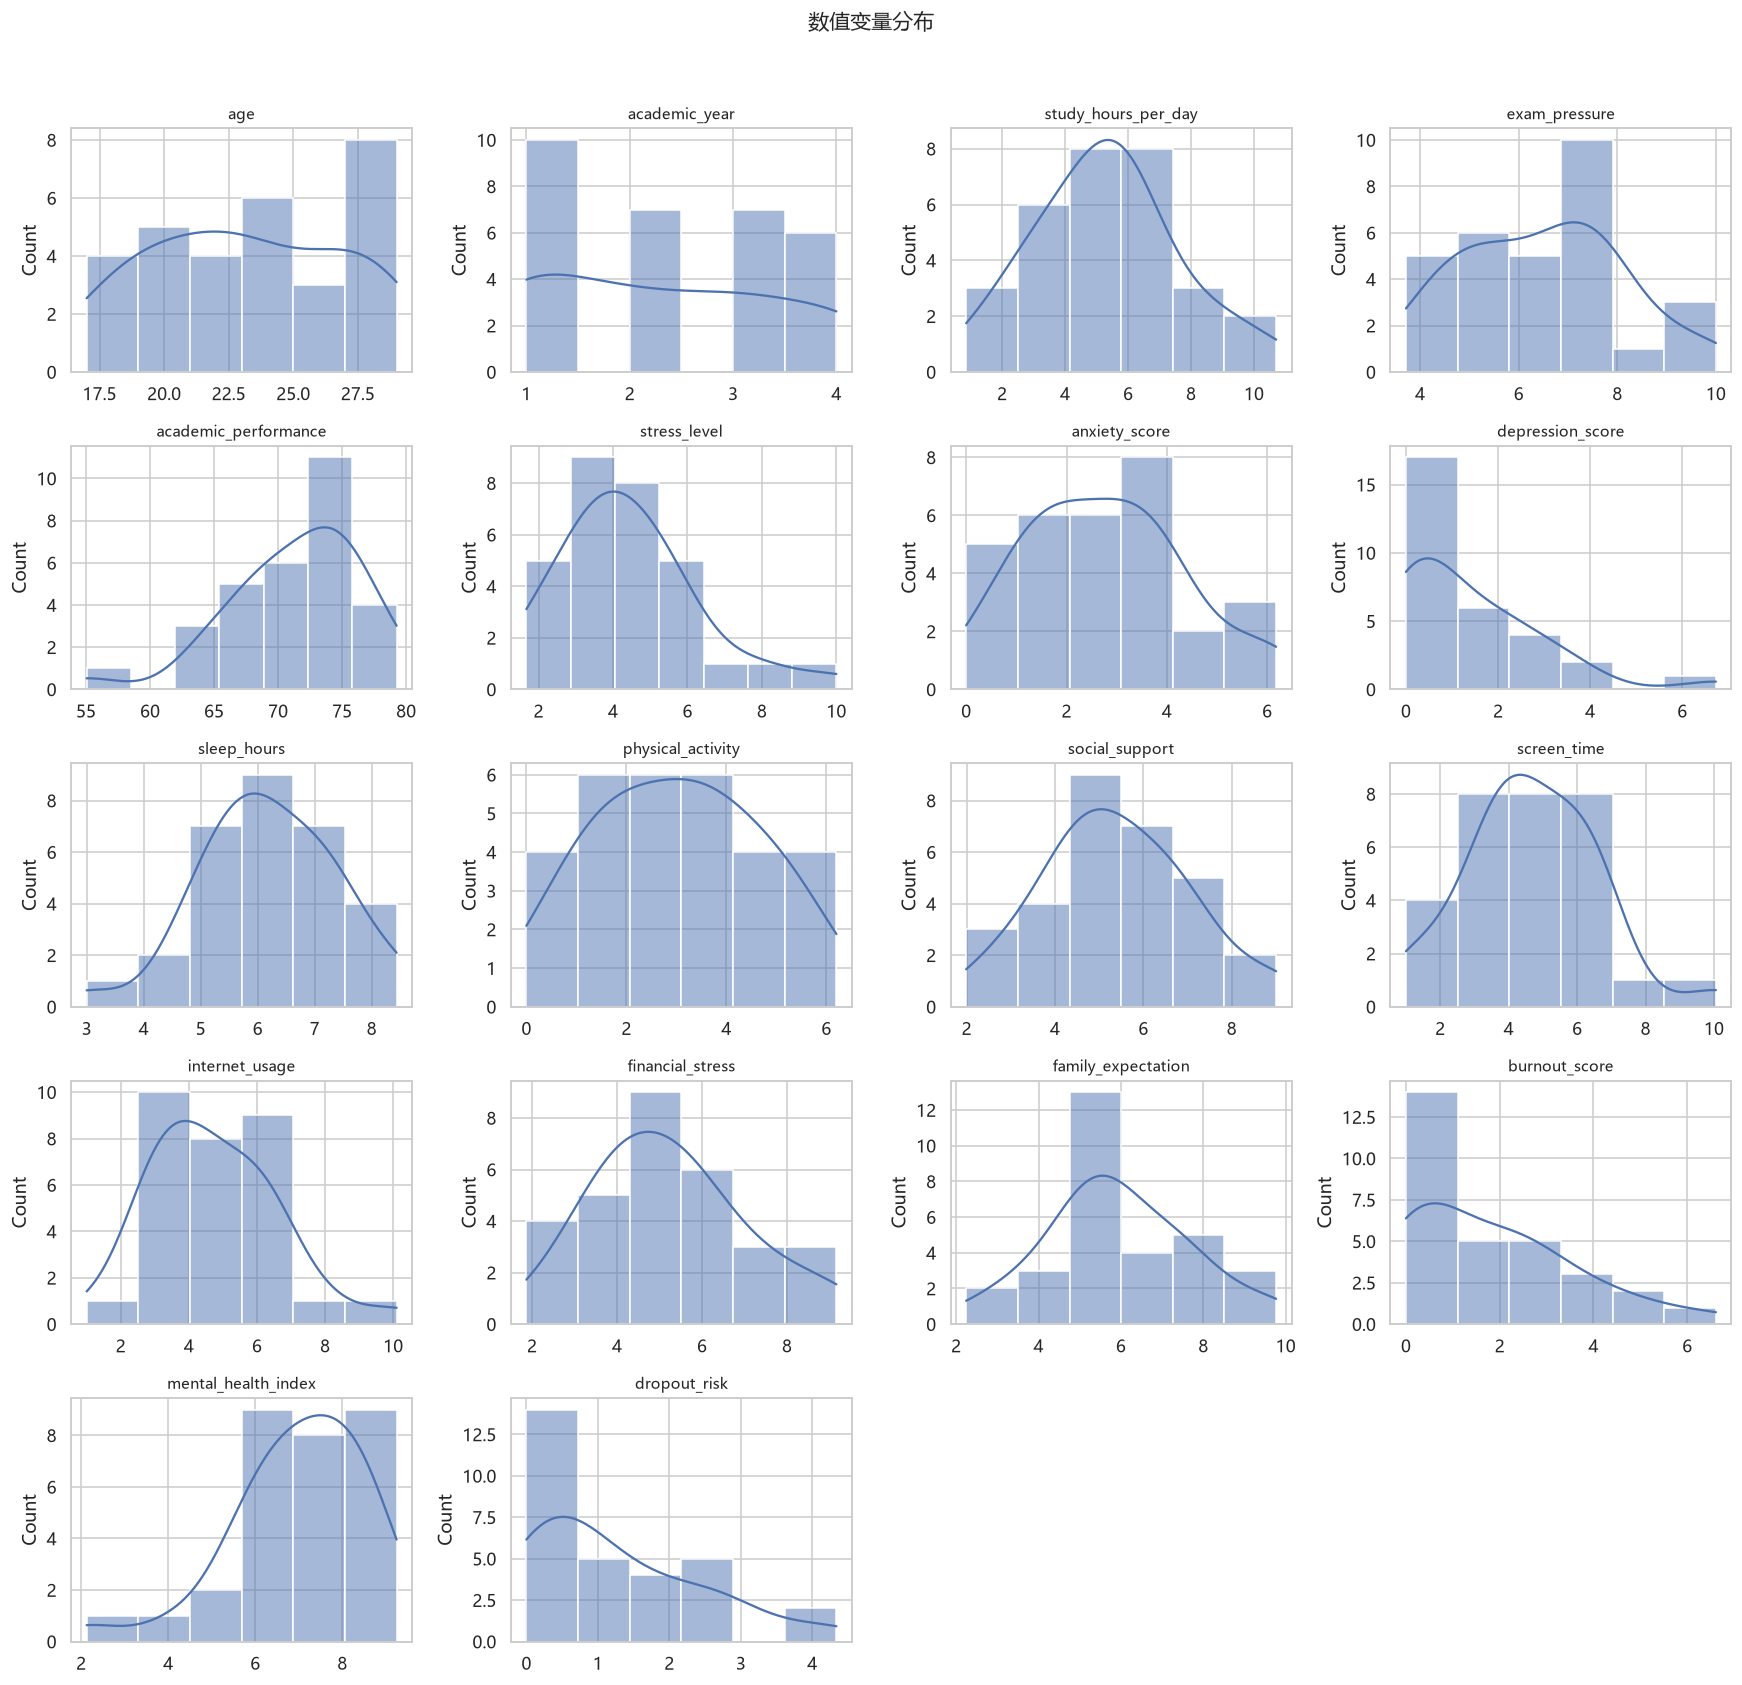

In [8]:
n = len(num_cols)
ncols = 4
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color="#4C72B0")
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel("")

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.suptitle("数值变量分布", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

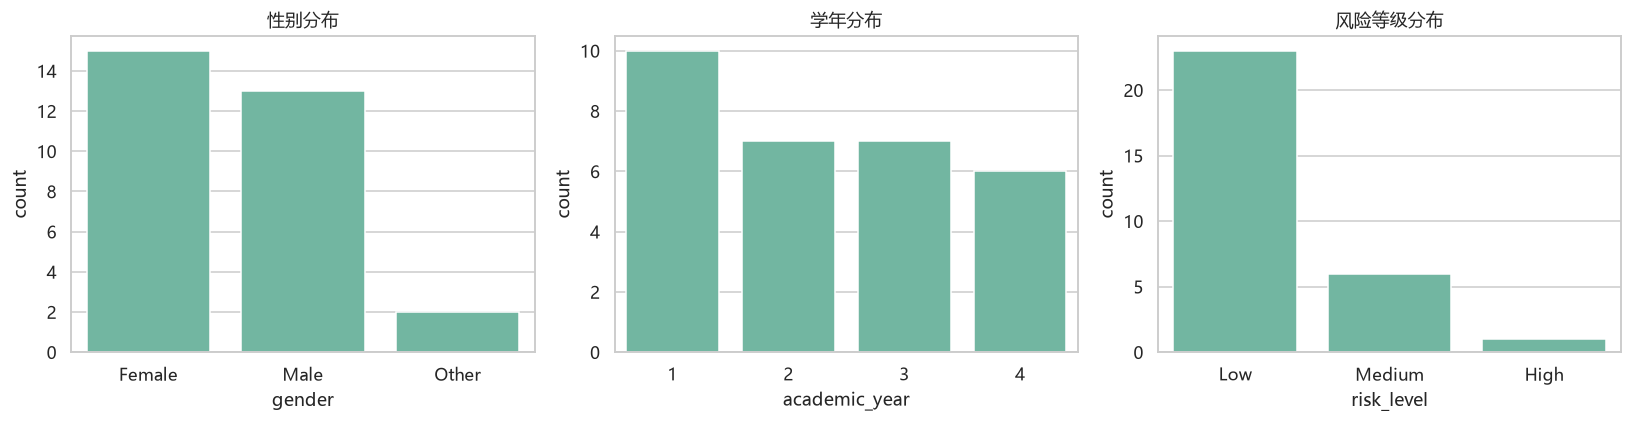

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 性别
sns.countplot(data=df, x="gender", ax=axes[0], order=df["gender"].value_counts().index)
axes[0].set_title("性别分布")

# 学年
sns.countplot(data=df, x="academic_year", ax=axes[1], order=sorted(df["academic_year"].dropna().unique()))
axes[1].set_title("学年分布")

# 风险等级
sns.countplot(data=df, x="risk_level", ax=axes[2], order=order_risk)
axes[2].set_title("风险等级分布")

plt.tight_layout()
plt.show()

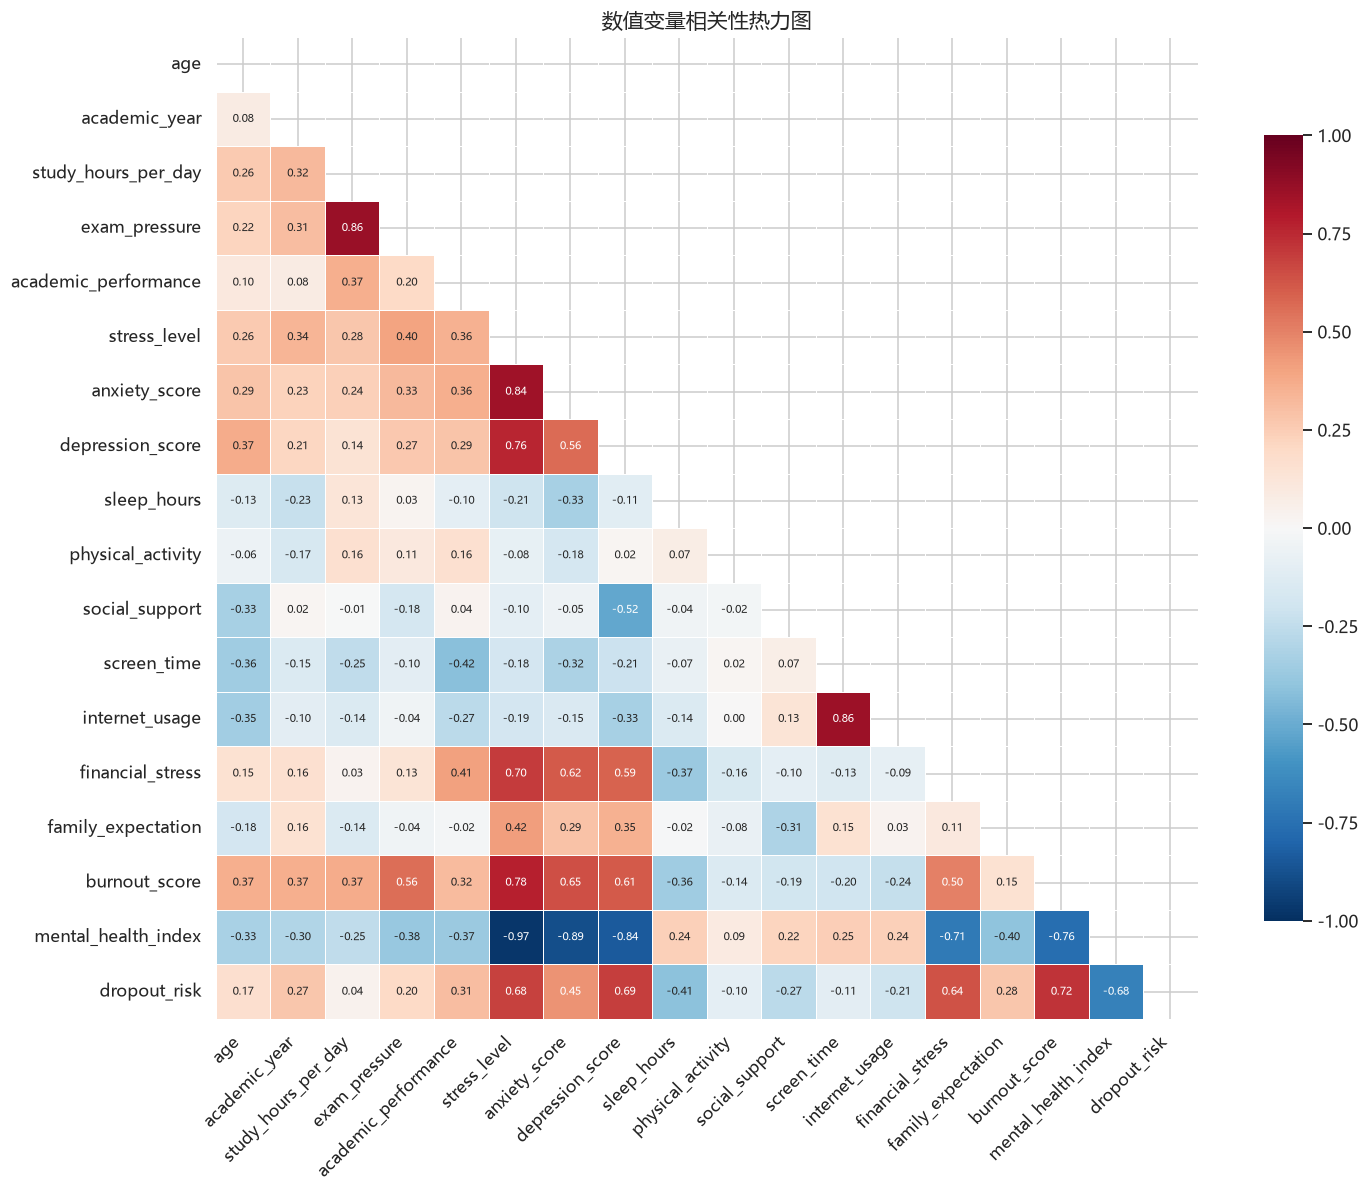

In [19]:
plt.figure(figsize=(14, 11))
corr = df[num_cols].corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))  # 只显示下三角
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f",
    cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
    annot_kws={"size": 7}
)

plt.xticks(rotation=45, ha="right")     
plt.title("数值变量相关性热力图", fontsize=14)
plt.tight_layout()
plt.show()

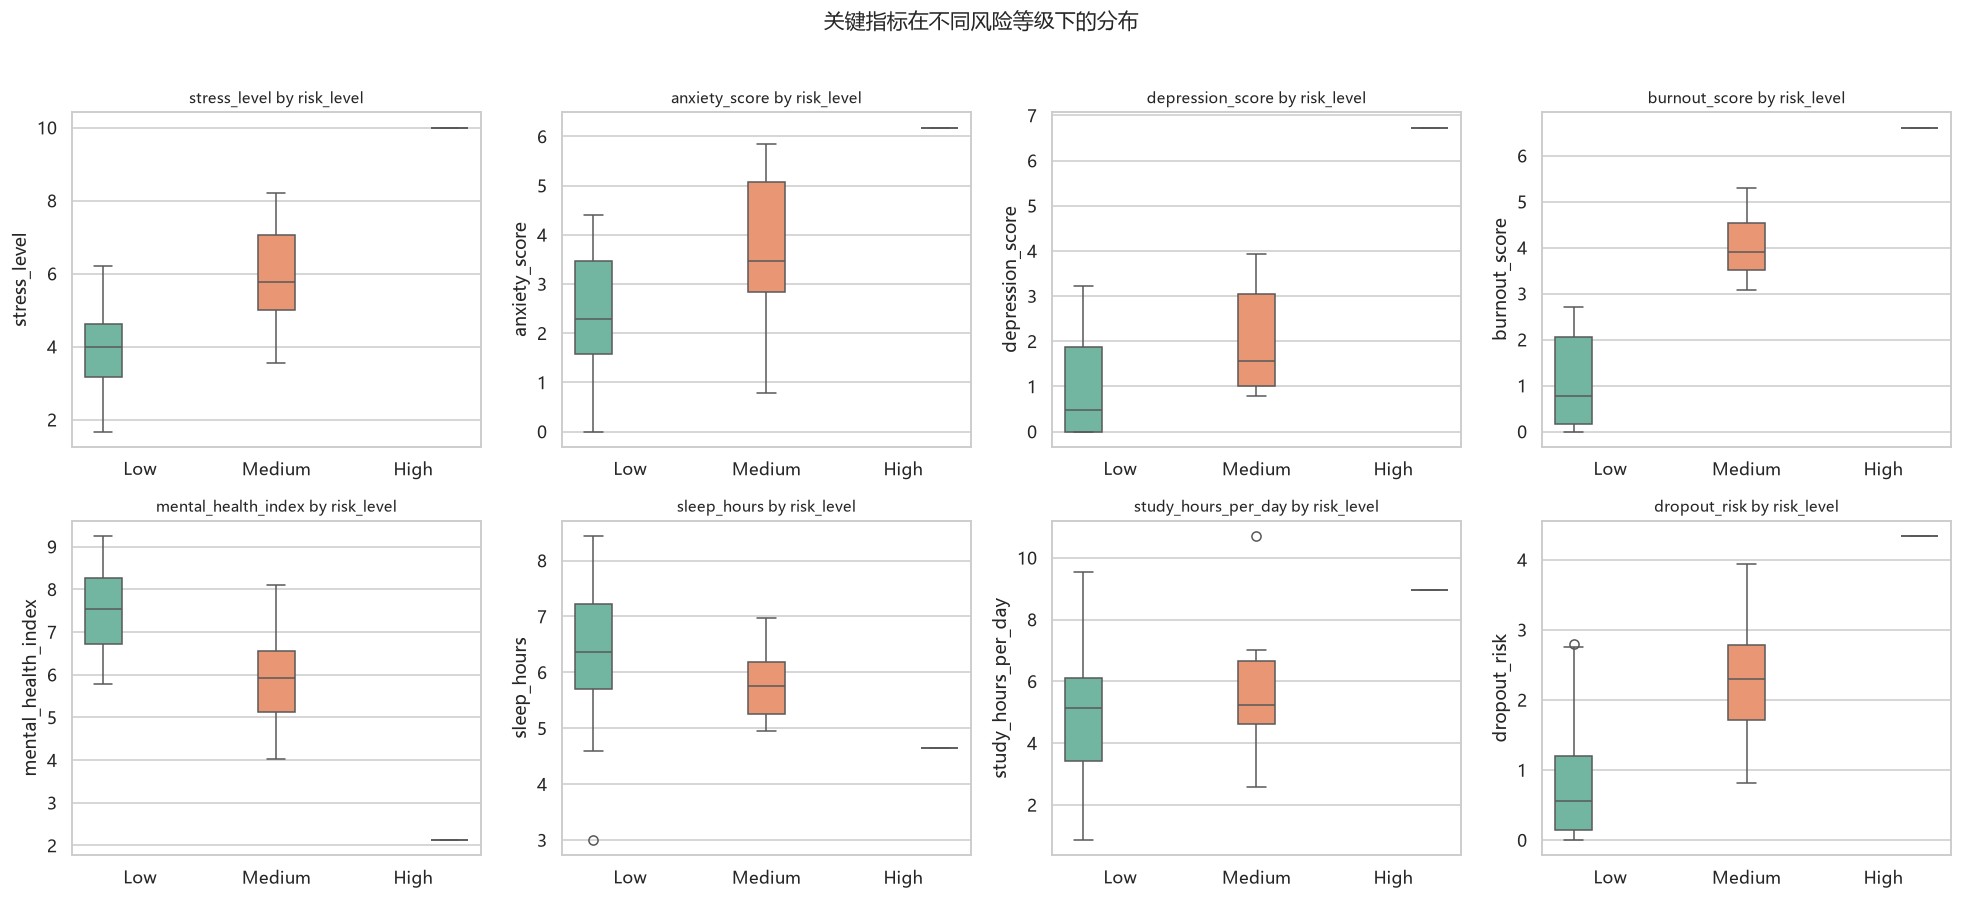

In [12]:
key_vars = [
    "stress_level", "anxiety_score", "depression_score", "burnout_score",
    "mental_health_index", "sleep_hours", "study_hours_per_day", "dropout_risk"
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(key_vars):
    sns.boxplot(
    data=df, x="risk_level", y=col,
    hue="risk_level", hue_order=order_risk,
    order=order_risk, ax=axes[i], palette="Set2",
    legend=False                      
)
    axes[i].set_title(f"{col} by risk_level", fontsize=10)
    axes[i].set_xlabel("")

plt.suptitle("关键指标在不同风险等级下的分布", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

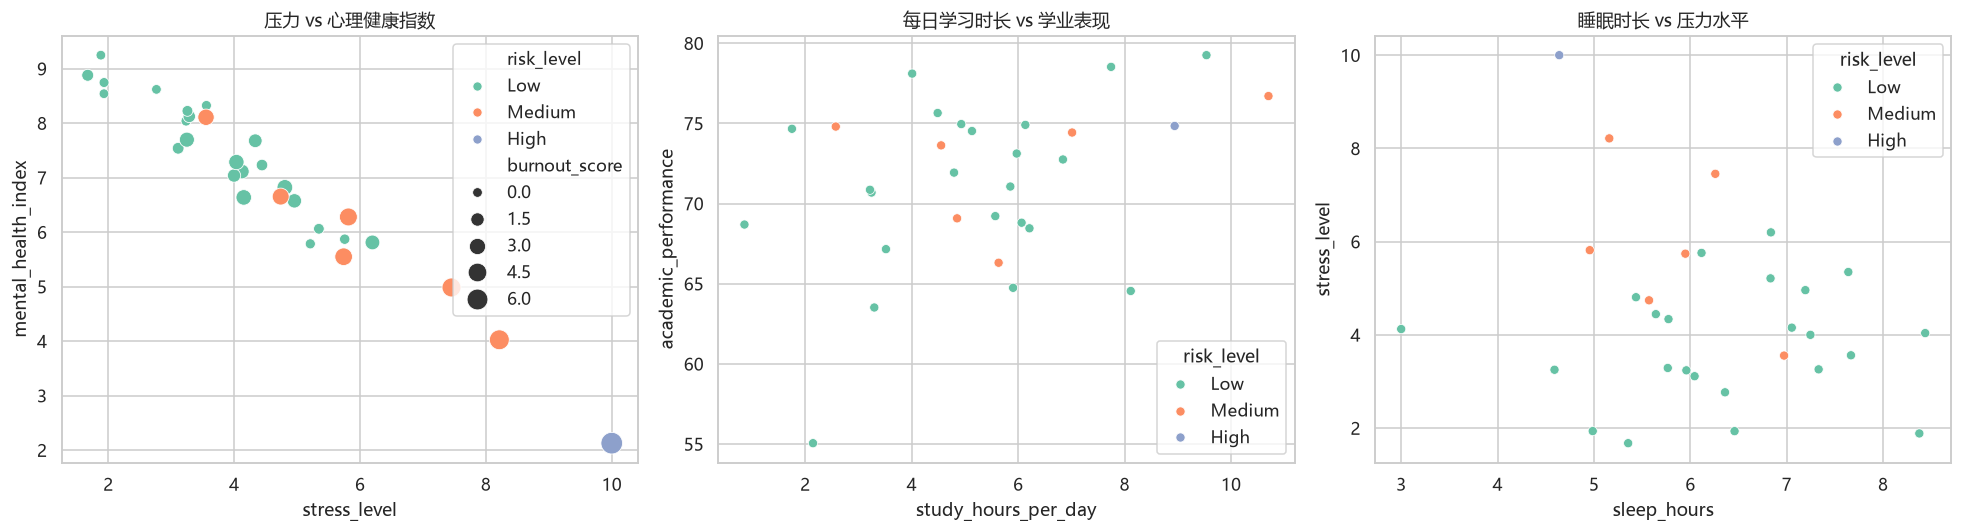

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(
    data=df, x="stress_level", y="mental_health_index",
    hue="risk_level", hue_order=order_risk,
    size="burnout_score", sizes=(40, 200), ax=axes[0]
)
axes[0].set_title("压力 vs 心理健康指数")

sns.scatterplot(
    data=df, x="study_hours_per_day", y="academic_performance",
    hue="risk_level", hue_order=order_risk, ax=axes[1]
)
axes[1].set_title("每日学习时长 vs 学业表现")

sns.scatterplot(
    data=df, x="sleep_hours", y="stress_level",
    hue="risk_level", hue_order=order_risk, ax=axes[2]
)
axes[2].set_title("睡眠时长 vs 压力水平")

plt.tight_layout()
plt.show()

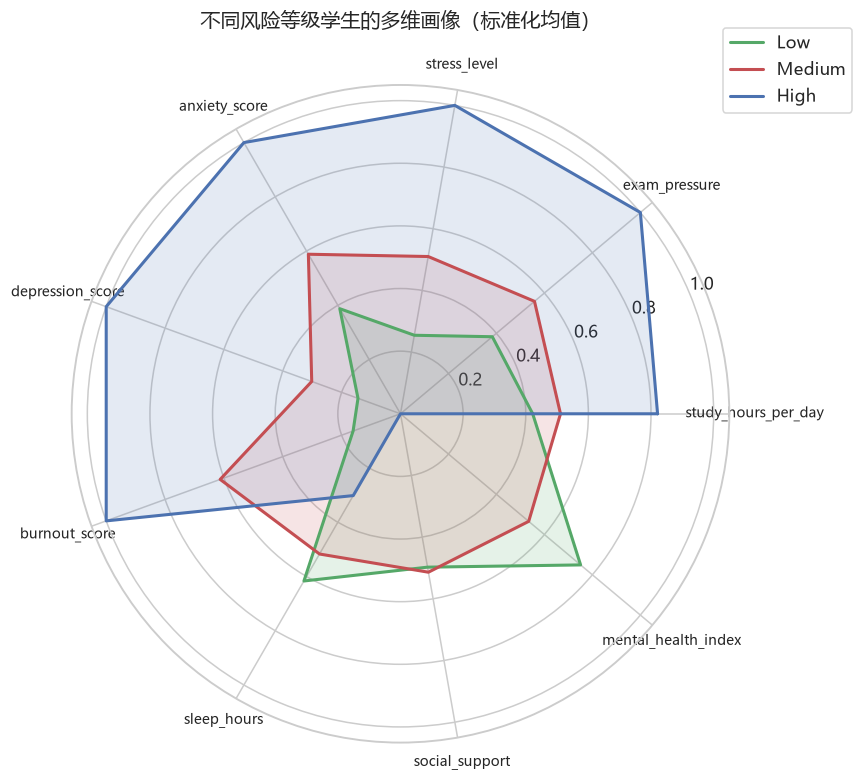

In [14]:
radar_vars = [
    "study_hours_per_day", "exam_pressure", "stress_level",
    "anxiety_score", "depression_score", "burnout_score",
    "sleep_hours", "social_support", "mental_health_index"
]

# 标准化到 0-1 便于比较
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
scaled = pd.DataFrame(
    scaler.fit_transform(df[radar_vars]),
    columns=radar_vars
)
scaled["risk_level"] = df["risk_level"].values

group_mean = scaled.groupby("risk_level").mean().reindex(order_risk)

angles = np.linspace(0, 2 * np.pi, len(radar_vars), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
colors = {"Low": "#55A868", "Medium": "#C44E52", "High": "#4C72B0"}

for risk in order_risk:
    values = group_mean.loc[risk].tolist()
    values += values[:1]
    ax.plot(angles, values, label=risk, color=colors[risk], linewidth=2)
    ax.fill(angles, values, color=colors[risk], alpha=0.15)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_vars, fontsize=9)
ax.set_title("不同风险等级学生的多维画像（标准化均值）", fontsize=13, pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.2, 1.1))
plt.tight_layout()
plt.show()

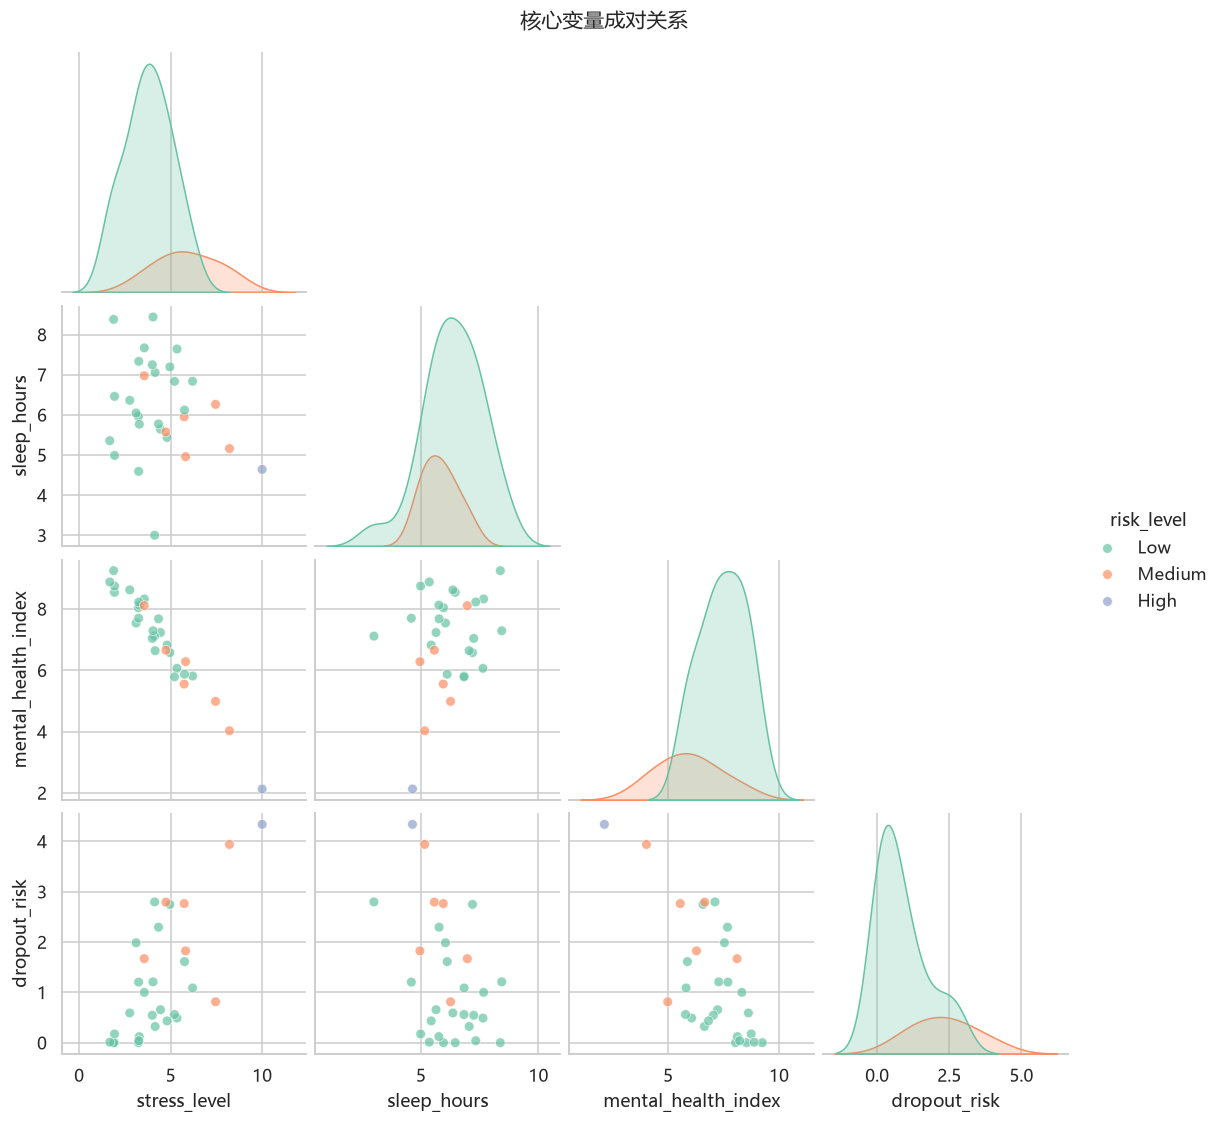

In [16]:
core = ["stress_level", "sleep_hours", "mental_health_index", "dropout_risk", "risk_level"]
sns.pairplot(
    df[core], hue="risk_level", hue_order=order_risk,
    palette="Set2", diag_kind="kde", corner=True,
    plot_kws={"alpha": 0.7, "s": 40}
)
plt.suptitle("核心变量成对关系", y=1.02, fontsize=14)
plt.show()

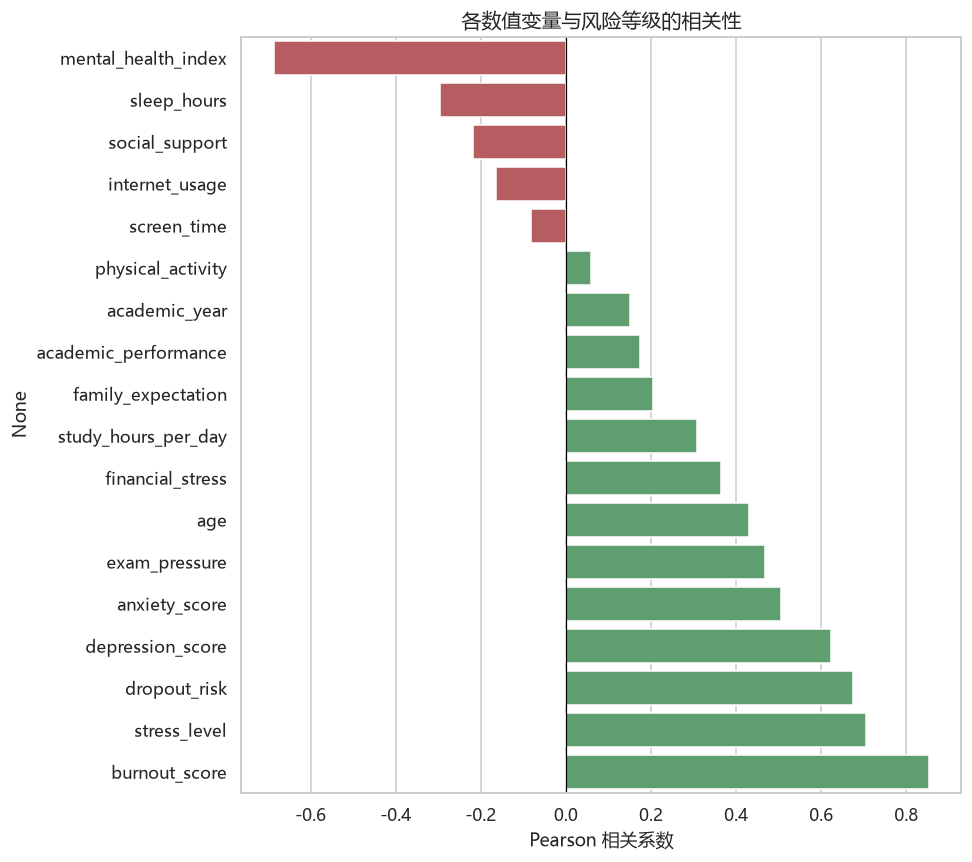

In [18]:
# 将 risk_level 映射为 0/1/2
risk_map = {"Low": 0, "Medium": 1, "High": 2}
df["risk_num"] = df["risk_level"].map(risk_map)

corr_with_risk = (
    df[num_cols + ["risk_num"]]
    .corr()["risk_num"]
    .drop("risk_num")
    .sort_values()
)

plt.figure(figsize=(9, 8))
colors_bar = ["#C44E52" if v < 0 else "#55A868" for v in corr_with_risk]

sns.barplot(
    x=corr_with_risk.values,
    y=corr_with_risk.index,
    hue=corr_with_risk.index,     # 横向图 → y 赋给 hue
    palette=colors_bar,
    dodge=False,
    legend=False
)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("各数值变量与风险等级的相关性", fontsize=13)
plt.xlabel("Pearson 相关系数")
plt.tight_layout()
plt.show()